### Assignment3 SVM Named Entity Recognition (NER) Tagger (with POS tag Vs without POS tag)

### Prof: Dr. Ye Kyaw Thu, Lab Leader, Language Understanding Lab., AI Mario, Myanmar
### Assignment3 submitted by: Khine Zar Thwe (AIEF-B2)
### Date: 02 September 2026

This notebook presents a comparative analysis of two Support Vector Machine (SVM)
sequence tagging models trained via LIBLINEAR / LinearSVC
on the myNER Burmese corpus:  
Model 1 (Without POS / 2-Column): Trains on token sequences directly mapping to NER target labels.

Model 2 (With POS / 3-Column): Incorporates Part-of-Speech (POS) tags into the feature window alongside word and n-gram representations to evaluate syntactic assistance for entity identification.  
The empirical goal is to evaluate whether providing explicitly tagged POS contextual features optimizes low-resource Myanmar entity recognition within an SVM pipeline.  

data set: https://github.com/ye-kyaw-thu/myNER

#library

In [ ]:
import time
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

from sklearn.feature_extraction import DictVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

*Load*

In [ ]:
def load_conll_data(filepath, include_pos=True):
    """
    Loads myNER CoNLL-formatted data.
    3-Column Mode: Word \t POS \t NER_Tag
    2-Column Mode: Word \t NER_Tag (or ignores column 2)
    """
    sentences = []
    current_sentence = []

    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                if current_sentence:
                    sentences.append(current_sentence)
                    current_sentence = []
                continue
            parts = line.split('\t')
            if len(parts) >= 3:
                word = parts[0]
                pos = parts[1] if include_pos else 'UNK'
                ner_tag = parts[2]
                current_sentence.append((word, pos, ner_tag))
            elif len(parts) == 2:
                word = parts[0]
                ner_tag = parts[1]
                current_sentence.append((word, 'UNK', ner_tag))

        if current_sentence:
            sentences.append(current_sentence)

    return sentences

In [ ]:
def extract_ner_features(sentences, use_pos_features=True):
    """
    Extracts Class 12 LIBLINEAR/LinearSVC style features with optional POS tags.
    """
    X_dict = []
    y_labels = []

    for sent in sentences:
        for i, (word, pos, ner_tag) in enumerate(sent):
            features = {
                'word': word,
                'prefix_1': word[:1],
                'prefix_2': word[:2],
                'suffix_1': word[-1:],
                'suffix_2': word[-2:],
                'is_first': i == 0,
                'is_last': i == len(sent) - 1,
            }

            # Left context
            if i > 0:
                features['prev_word'] = sent[i - 1][0]
            else:
                features['prev_word'] = '<BOS>'

            # Right context
            if i < len(sent) - 1:
                features['next_word'] = sent[i + 1][0]
            else:
                features['next_word'] = '<EOS>'

            # Optional POS contextual features
            if use_pos_features:
                features['pos'] = pos
                features['prev_pos'] = sent[i - 1][1] if i > 0 else '<BOS_POS>'
                features['next_pos'] = sent[i + 1][1] if i < len(sent) - 1 else '<EOS_POS>'

            X_dict.append(features)
            y_labels.append(ner_tag)

    return X_dict, y_labels

In [ ]:
def run_model(train_file, test_file, use_pos=True, model_name="Model"):
    print(f"\n==================================================")
    print(f" Running {model_name} (POS Features = {use_pos})")
    print(f"==================================================")

    train_sents = load_conll_data(train_file, include_pos=use_pos)
    test_sents = load_conll_data(test_file, include_pos=use_pos)

    X_train_dict, y_train = extract_ner_features(train_sents, use_pos_features=use_pos)
    X_test_dict, y_test = extract_ner_features(test_sents, use_pos_features=use_pos)

    vectorizer = DictVectorizer(sparse=True)
    X_train = vectorizer.fit_transform(X_train_dict)
    X_test = vectorizer.transform(X_test_dict)

    clf = LinearSVC(C=1.0, max_iter=1000, random_state=42)

    t0 = time.time()
    clf.fit(X_train, y_train)
    train_time = time.time() - t0

    y_pred = clf.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    weighted_f1 = f1_score(y_test, y_pred, average='weighted')

    report_dict = classification_report(y_test, y_pred, zero_division=0, output_dict=True)

    return {
        'model_name': model_name,
        'y_test': y_test,
        'y_pred': y_pred,
        'accuracy': acc,
        'macro_f1': macro_f1,
        'weighted_f1': weighted_f1,
        'train_time': train_time,
        'report_dict': report_dict,
        'labels': sorted(list(set(y_test)))
    }

In [ ]:
def plot_confusion_matrices(res1, res2):
    """Plots side-by-side normalized confusion matrices."""
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    for ax, res in zip(axes, [res1, res2]):
        labels = res['labels']
        cm = confusion_matrix(res['y_test'], res['y_pred'], labels=labels, normalize='true')

        sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax)
        ax.set_title(f"Confusion Matrix: {res['model_name']}", fontsize=12, fontweight='bold')
        ax.set_xlabel("Predicted Tag")
        ax.set_ylabel("True Tag")

    plt.tight_layout()
    plt.savefig("confusion_matrices.png", dpi=300)
    plt.show()

In [ ]:
def plot_per_tag_f1_comparison(res1, res2):
    """Plots a bar chart comparing F1-scores per tag between both models."""
    tags = [t for t in res1['labels'] if t not in ['accuracy', 'macro avg', 'weighted avg']]

    f1_m1 = [res1['report_dict'][t]['f1-score'] for t in tags]
    f1_m2 = [res2['report_dict'][t]['f1-score'] for t in tags]

    df = pd.DataFrame({
        'Tag': tags * 2,
        'F1-Score': f1_m1 + f1_m2,
        'Model': ['Model 1 (Without POS)'] * len(tags) + ['Model 2 (With POS)'] * len(tags)
    })

    plt.figure(figsize=(12, 6))
    sns.barplot(data=df, x='Tag', y='F1-Score', hue='Model', palette='Set2')
    plt.title("Per-Tag F1-Score Comparison (Without POS vs. With POS)", fontsize=14, fontweight='bold')
    plt.ylim(0, 1.05)
    plt.ylabel("F1-Score")
    plt.xlabel("NER Tag")
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.savefig("per_tag_f1_comparison.png", dpi=300)
    plt.show()

In [ ]:
def plot_overall_metrics(res1, res2):
    """Plots overall Accuracy, Macro F1, and Weighted F1 comparison."""
    metrics = ['Accuracy', 'Macro F1', 'Weighted F1']

    m1_scores = [res1['accuracy'], res1['macro_f1'], res1['weighted_f1']]
    m2_scores = [res2['accuracy'], res2['macro_f1'], res2['weighted_f1']]

    df = pd.DataFrame({
        'Metric': metrics * 2,
        'Score': m1_scores + m2_scores,
        'Model': ['Model 1 (Without POS)'] * 3 + ['Model 2 (With POS)'] * 3
    })

    plt.figure(figsize=(8, 5))
    ax = sns.barplot(data=df, x='Metric', y='Score', hue='Model', palette='viridis')
    plt.title("Overall Performance Summary", fontsize=14, fontweight='bold')
    plt.ylim(0, 1.05)
    plt.ylabel("Score")
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Annotate bar values
    for p in ax.patches:
        if p.get_height() > 0:
            ax.annotate(f"{p.get_height():.4f}",
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', xytext=(0, 5),
                        textcoords='offset points', fontsize=9)

    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.savefig("overall_metrics.png", dpi=300)
    plt.show()


 Running Model 1 (Without POS) (POS Features = False)


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(



 Running Model 2 (With POS) (POS Features = True)


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(



[Visualizations] Generating Confusion Matrices...


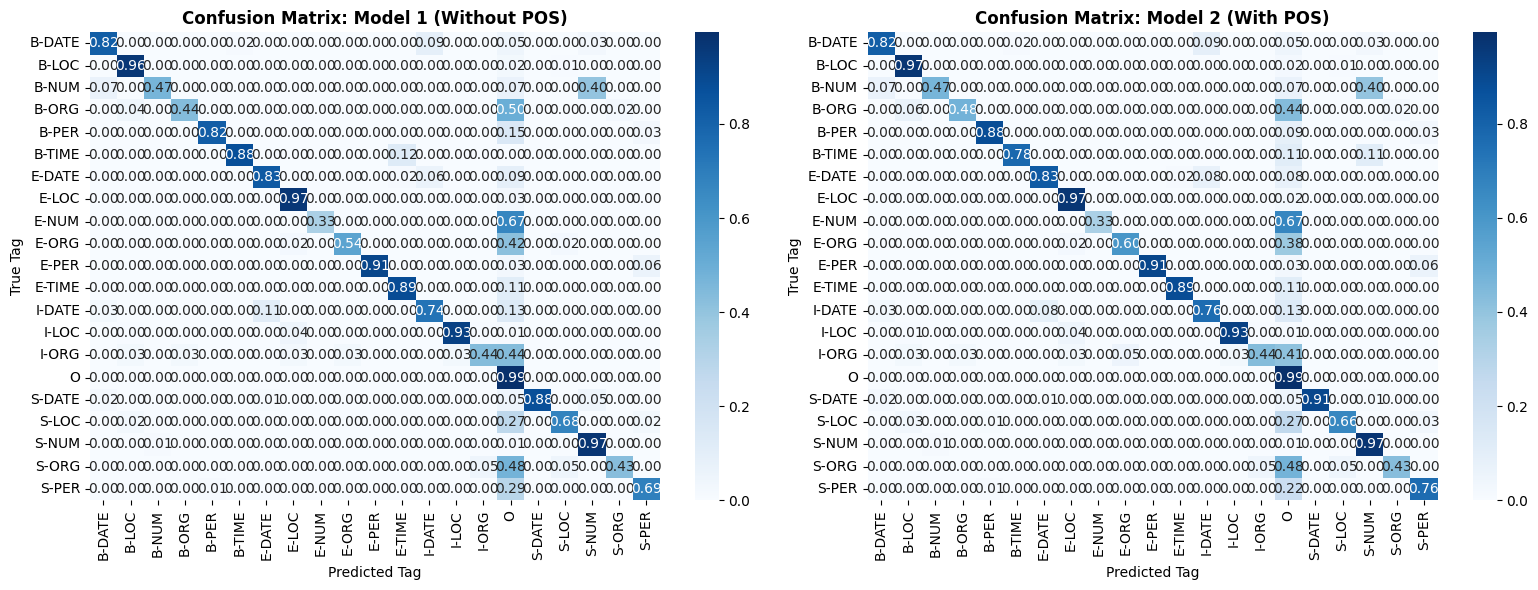

[Visualizations] Generating Per-Tag F1-Score Chart...


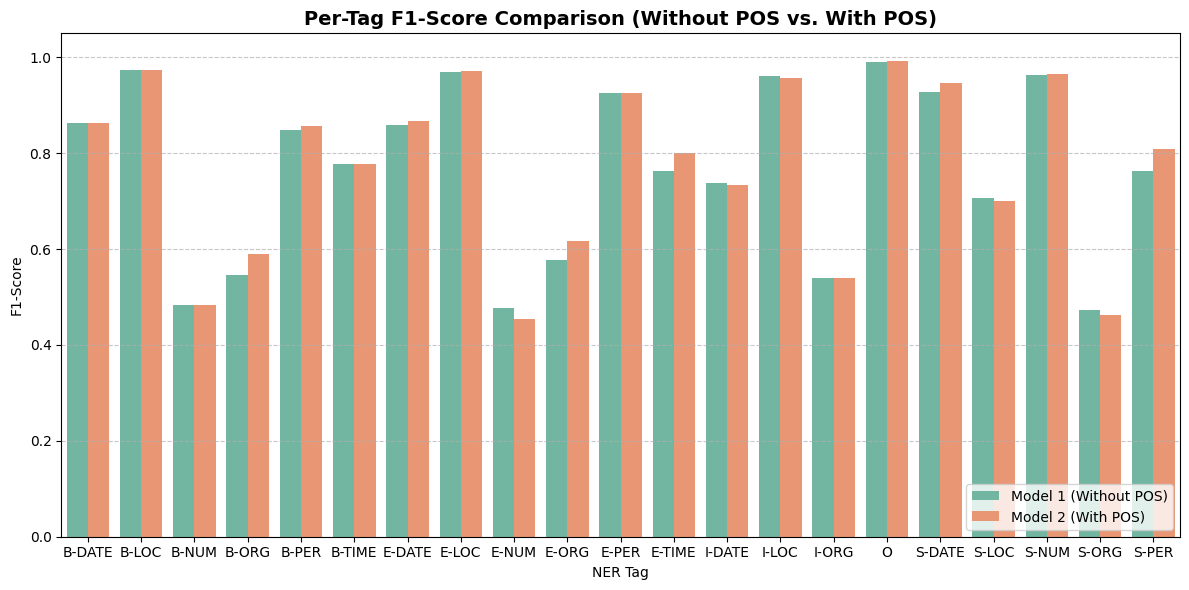

[Visualizations] Generating Overall Metrics Chart...


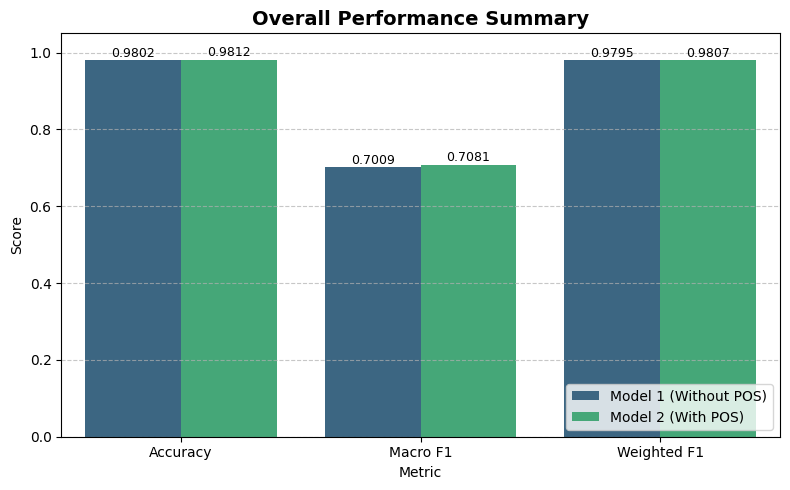

In [ ]:
def main():
    train_path = "/content/drive/MyDrive/assignment3_data/train_v5.conll"
    test_path = "/content/drive/MyDrive/assignment3_data/test_v5.conll"

    # Run Model 1 & Model 2
    res1 = run_model(train_path, test_path, use_pos=False, model_name="Model 1 (Without POS)")
    res2 = run_model(train_path, test_path, use_pos=True, model_name="Model 2 (With POS)")

    # Generate Visualizations
    print("\n[Visualizations] Generating Confusion Matrices...")
    plot_confusion_matrices(res1, res2)

    print("[Visualizations] Generating Per-Tag F1-Score Chart...")
    plot_per_tag_f1_comparison(res1, res2)

    print("[Visualizations] Generating Overall Metrics Chart...")
    plot_overall_metrics(res1, res2)

if __name__ == '__main__':
    main()